# DICOM EDA: чтение одного файла и просмотр исследования

`study` в DICOM обычно означает одно исследование/визит пациента: внутри него могут быть одна или несколько `series`, а внутри серии - один или несколько DICOM-объектов/изображений. В этом датасете `разметка.xlsx` размечает именно `study`, а внутри каждого `study` лежит несколько `.dcm`, поэтому при обучении и валидации важно группировать данные по `study`, чтобы не было leakage.

Ниже код читает DICOM прямо из `.zip`, показывает метаданные одного файла и визуализирует все изображения внутри выбранного исследования.


## 1. Импорты и пути

Если `pydicom` или `matplotlib` не установлены, установи зависимости, например:

```bash
uv add pydicom matplotlib pandas numpy
```


In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pydicom
from pydicom.pixel_data_handlers.util import apply_voi_lut

warnings.filterwarnings("ignore", category=UserWarning)


def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists() and (path / "data").exists():
            return path
    raise FileNotFoundError("Не нашел корень проекта с pyproject.toml и data/")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"
TRAIN_ZIP = DATA_DIR / "НД_для_обучения.zip"
TEST_ZIP = DATA_DIR / "Для теста.zip"

ROOT, TRAIN_ZIP.exists(), TEST_ZIP.exists()


(PosixPath('/home/s0ft44/projects/densitometry'), True, True)

## 2. Посмотрим, какие DICOM лежат в архивах

In [2]:
def list_dicom_members(zip_path: Path) -> list[str]:
    with ZipFile(zip_path) as zf:
        return [name for name in zf.namelist() if name.lower().endswith(".dcm")]


def parse_member_path(member: str) -> dict:
    parts = member.split("/")
    info = {
        "member": member,
        "filename": parts[-1],
        "study_folder": None,
        "series_folder": None,
    }
    if len(parts) >= 3 and parts[0] == "Исследования":
        info["study_folder"] = parts[1]
        info["series_folder"] = parts[2]
    return info


train_members = list_dicom_members(TRAIN_ZIP)
test_members = list_dicom_members(TEST_ZIP)

print(f"train DICOM: {len(train_members)}")
print(f"test DICOM:  {len(test_members)}")

pd.DataFrame([parse_member_path(m) for m in train_members]).head(10)


train DICOM: 499
test DICOM:  3


,member,filename,study_folder,series_folder
0,Исследования/1.2.840.113619.2.110.512719.20250...,CR000000.dcm,1.2.840.113619.2.110.512719.20250403090444,series_004_3_CR
1,Исследования/1.2.840.113619.2.110.512719.20250...,CR000001.dcm,1.2.840.113619.2.110.512719.20250403090444,series_004_3_CR
2,Исследования/1.2.840.113619.2.110.512719.20250...,CR000002.dcm,1.2.840.113619.2.110.512719.20250403090444,series_004_3_CR
3,Исследования/1.2.840.113619.2.110.512719.20250...,CR000003.dcm,1.2.840.113619.2.110.512719.20250403090444,series_004_3_CR
4,Исследования/1.2.840.113619.2.110.512719.20250...,CR000004.dcm,1.2.840.113619.2.110.512719.20250403090444,series_004_3_CR
5,Исследования/1.2.840.113619.2.110.512719.20250...,CR000005.dcm,1.2.840.113619.2.110.512719.20250403090444,series_004_3_CR
6,Исследования/1.2.840.113619.2.110.512719.20250...,CR000000.dcm,1.2.840.113619.2.110.512719.20250403092052,series_003_3_CR
7,Исследования/1.2.840.113619.2.110.512719.20250...,CR000001.dcm,1.2.840.113619.2.110.512719.20250403092052,series_003_3_CR
8,Исследования/1.2.840.113619.2.110.512719.20250...,CR000002.dcm,1.2.840.113619.2.110.512719.20250403092052,series_003_3_CR
9,Исследования/1.2.840.113619.2.110.512719.20250...,CR000003.dcm,1.2.840.113619.2.110.512719.20250403092052,series_003_3_CR


## 3. Чтение одного DICOM из zip

`stop_before_pixels=False` читает и метаданные, и пиксели. Если нужны только метаданные, можно поставить `True`.


In [3]:
def read_dicom_from_zip(zip_path: Path, member: str, stop_before_pixels: bool = False) -> pydicom.Dataset:
    with ZipFile(zip_path) as zf:
        raw = zf.read(member)
    return pydicom.dcmread(BytesIO(raw), stop_before_pixels=stop_before_pixels, force=True)


# Можно заменить индекс или member на любой файл из train_members / test_members.
zip_path = TRAIN_ZIP
member = train_members[9]

ds = read_dicom_from_zip(zip_path, member)
print(member)
print(ds)


Исследования/1.2.840.113619.2.110.512719.20250403092052/series_003_3_CR/DXA/CR DXA/CR000003.dcm
Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 206
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Computed Radiography Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.643.5.1.13.13.12.2.77.8252.07120303070106110214090814060908
(0002,0010) Transfer Syntax UID                 UI: Implicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.8
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_368'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 144'
(0008,0016) SOP Class UID                       UI: Computed Radiography Image Storage
(0008,0018) SOP Instance UID                    UI: 1.2.643.5.1.13.13.12.2.77.8252.071203030701061102

## 4. Ключевые метаданные

Самые полезные поля для пайплайна: `StudyInstanceUID`, `SeriesInstanceUID`, `SOPInstanceUID`, размеры изображения, `PixelSpacing`, modality и текстовые описания. В этом датасете часть клинических тегов может быть пустой или обезличенной.


In [4]:
KEY_TAGS = [
    "PatientID",
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "SOPInstanceUID",
    "Modality",
    "Manufacturer",
    "StationName",
    "DeviceSerialNumber",
    "SoftwareVersions",
    "StudyDescription",
    "SeriesDescription",
    "ProtocolName",
    "BodyPartExamined",
    "ViewPosition",
    "Rows",
    "Columns",
    "NumberOfFrames",
    "SamplesPerPixel",
    "PhotometricInterpretation",
    "BitsAllocated",
    "BitsStored",
    "PixelRepresentation",
    "PixelSpacing",
    "ImagerPixelSpacing",
    "PixelAspectRatio",
    "RescaleSlope",
    "RescaleIntercept",
    "WindowCenter",
    "WindowWidth",
]


def get_tag_value(ds: pydicom.Dataset, name: str):
    value = getattr(ds, name, None)
    if value is None:
        return None
    if isinstance(value, pydicom.multival.MultiValue):
        return list(value)
    return value


meta_df = pd.DataFrame(
    [{"tag": tag, "value": get_tag_value(ds, tag)} for tag in KEY_TAGS]
)
meta_df


,tag,value
0,PatientID,Anonymized
1,StudyInstanceUID,1.2.643.5.1.13.13.12.2.77.8252.060008051306070...
2,SeriesInstanceUID,1.2.643.5.1.13.13.12.2.77.8252.050407081410111...
3,SOPInstanceUID,1.2.643.5.1.13.13.12.2.77.8252.071203030701061...
4,Modality,CR
5,Manufacturer,GE Healthcare
6,StationName,Anonymized
7,DeviceSerialNumber,Anonymized
8,SoftwareVersions,18.50.082
9,StudyDescription,DXA Обследование


## 4.1 Почему выбраны эти метаданные

Для QC-пайплайна нам нужны три группы DICOM-тегов:

1. Идентификаторы: связывают файл с исследованием и серией. Это `StudyInstanceUID`, `SeriesInstanceUID`, `SOPInstanceUID`.
2. Признаки области/проекции: потенциально помогают понять, позвоночник это или бедро, правая/левая сторона, какая укладка/проекция. Это `BodyPartExamined`, `ViewPosition`, `Laterality`, `ImageLaterality`, `PatientPosition`, `StudyDescription`, `SeriesDescription`, `ProtocolName`.
3. Признаки пикселей и геометрии: нужны для чтения изображения и перевода пикселей в миллиметры, если масштаб есть в DICOM. Это `Rows`, `Columns`, `PixelSpacing`, `ImagerPixelSpacing`, `NominalScannedPixelSpacing`, `DetectorElementSpacing`, `BitsAllocated`, `BitsStored`, `PhotometricInterpretation`.

Важно: эти теги надо не просто выбрать теоретически, а проверить на реальных данных. Следующая ячейка сканирует архив и показывает уникальные значения.


In [5]:
ANATOMY_PROJECTION_TAGS = [
    "StudyDescription",
    "SeriesDescription",
    "ProtocolName",
    "BodyPartExamined",
    "ViewPosition",
    "PatientPosition",
    "Laterality",
    "ImageLaterality",
]

DEVICE_TAGS = [
    "Manufacturer",
    "StationName",
    "DeviceSerialNumber",
    "SoftwareVersions",
]

IDENTIFIER_TAGS = [
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "SOPInstanceUID",
]

PIXEL_GEOMETRY_TAGS = [
    "Rows",
    "Columns",
    "NumberOfFrames",
    "PixelSpacing",
    "ImagerPixelSpacing",
    "PixelAspectRatio",
    "NominalScannedPixelSpacing",
    "DetectorElementSpacing",
    "PhotometricInterpretation",
    "BitsAllocated",
    "BitsStored",
]

SCAN_TAGS = IDENTIFIER_TAGS + DEVICE_TAGS + ANATOMY_PROJECTION_TAGS + PIXEL_GEOMETRY_TAGS


def simplify_dicom_value(value):
    if value is None:
        return None
    if isinstance(value, pydicom.multival.MultiValue):
        return "\".join(str(v) for v in value)
    if isinstance(value, (list, tuple)):
        return "\".join(str(v) for v in value)
    return str(value)


def scan_dicom_metadata(zip_path: Path, members: list[str], tags: list[str]) -> pd.DataFrame:
    rows = []
    with ZipFile(zip_path) as zf:
        for member in members:
            ds_meta = pydicom.dcmread(BytesIO(zf.read(member)), stop_before_pixels=True, force=True)
            row = parse_member_path(member)
            for tag in tags:
                row[tag] = simplify_dicom_value(getattr(ds_meta, tag, None))
            rows.append(row)
    return pd.DataFrame(rows)


def metadata_unique_summary(df: pd.DataFrame, tags: list[str], max_examples: int = 8) -> pd.DataFrame:
    rows = []
    for tag in tags:
        s = df[tag].fillna("<MISSING>")
        nonempty = s[~s.isin(["", "<MISSING>"])]
        counts = s.value_counts(dropna=False)
        examples = "; ".join(f"{value!r}: {count}" for value, count in counts.head(max_examples).items())
        rows.append({
            "tag": tag,
            "unique": int(s.nunique(dropna=False)),
            "non_missing": int((s != "<MISSING>").sum()),
            "non_empty": int(len(nonempty)),
            "top_values": examples,
        })
    return pd.DataFrame(rows)


train_meta_df = scan_dicom_metadata(TRAIN_ZIP, train_members, SCAN_TAGS)
test_meta_df = scan_dicom_metadata(TEST_ZIP, test_members, SCAN_TAGS)

metadata_unique_summary(train_meta_df, ANATOMY_PROJECTION_TAGS + PIXEL_GEOMETRY_TAGS)


SyntaxError: unterminated string literal (detected at line 46) (1207685579.py, line 46)

### Вывод для текущих данных

Если в summary у тегов `BodyPartExamined`, `ViewPosition`, `Laterality`, `ImageLaterality` значения пустые или `<MISSING>`, то на них нельзя опираться для определения области/проекции. Тогда область нужно определять по изображению, а метаданные использовать только как вспомогательный источник.

Для тестового архива можно отдельно посмотреть такую же сводку:

In [ ]:
metadata_unique_summary(test_meta_df, ANATOMY_PROJECTION_TAGS + PIXEL_GEOMETRY_TAGS)


## 4.2 Производитель, масштаб и private-теги

Перед тем как считать, что миллиметров нет, проверяем шире:

- `Manufacturer`, `SoftwareVersions`: какой аппарат/ПО;
- `PixelSpacing`, `ImagerPixelSpacing`, `PixelAspectRatio` и похожие теги масштаба;
- private-теги производителя. У GE Lunar/Hologic геометрия иногда может быть в private-полях, но на них нужно опираться осторожно: закрытый тест может быть с другим экспортом или другой версией ПО.


In [ ]:
DEVICE_AND_GEOMETRY_TAGS = [
    "Manufacturer",
    "StationName",
    "DeviceSerialNumber",
    "SoftwareVersions",
    "Rows",
    "Columns",
    "PixelSpacing",
    "ImagerPixelSpacing",
    "PixelAspectRatio",
    "NominalScannedPixelSpacing",
    "DetectorElementSpacing",
]

metadata_unique_summary(train_meta_df, DEVICE_AND_GEOMETRY_TAGS)


In [ ]:
def scan_private_tags(zip_path: Path, members: list[str], max_files: int | None = None) -> pd.DataFrame:
    rows = []
    selected_members = members if max_files is None else members[:max_files]

    with ZipFile(zip_path) as zf:
        for member in selected_members:
            ds_private = pydicom.dcmread(BytesIO(zf.read(member)), stop_before_pixels=True, force=True)
            for elem in ds_private.iterall():
                if not elem.tag.is_private:
                    continue

                value = str(elem.value)
                if len(value) > 200:
                    value = value[:200] + "..."

                rows.append({
                    "member": member,
                    "tag": str(elem.tag),
                    "group": f"{elem.tag.group:04X}",
                    "element": f"{elem.tag.element:04X}",
                    "VR": elem.VR,
                    "keyword": elem.keyword,
                    "name": elem.name,
                    "value": value,
                })

    return pd.DataFrame(rows)


private_train_df = scan_private_tags(TRAIN_ZIP, train_members)
print(f"private tags rows: {len(private_train_df)}")
private_train_df.head(50)


In [ ]:
if len(private_train_df):
    private_summary = (
        private_train_df
        .groupby(["tag", "VR", "name"], as_index=False)
        .agg(
            n_files=("member", "nunique"),
            n_values=("value", "nunique"),
            examples=("value", lambda x: "; ".join(map(repr, list(pd.Series(x).drop_duplicates().head(5)))))
        )
        .sort_values(["n_files", "tag"], ascending=[False, True])
    )
    display(private_summary.head(100))
else:
    print("Private-теги в переданных DICOM не найдены.")


## 5. Пиксели и нормализация для просмотра

In [ ]:
def dicom_to_array(ds: pydicom.Dataset, apply_voi: bool = True) -> np.ndarray:
    # Возвращает pixel_array как float32. Поддерживает single-frame и multi-frame DICOM.
    arr = ds.pixel_array

    if apply_voi:
        try:
            arr = apply_voi_lut(arr, ds)
        except Exception:
            pass

    arr = arr.astype(np.float32)

    slope = float(getattr(ds, "RescaleSlope", 1.0) or 1.0)
    intercept = float(getattr(ds, "RescaleIntercept", 0.0) or 0.0)
    arr = arr * slope + intercept

    return arr


def normalize_for_display(arr: np.ndarray, low: float = 1, high: float = 99) -> np.ndarray:
    # Percentile clipping -> [0, 1] для стабильной визуализации.
    arr = arr.astype(np.float32)
    lo, hi = np.percentile(arr, [low, high])
    if hi <= lo:
        lo, hi = float(arr.min()), float(arr.max())
    if hi <= lo:
        return np.zeros_like(arr, dtype=np.float32)
    return np.clip((arr - lo) / (hi - lo), 0, 1)


arr = dicom_to_array(ds)
arr.shape, arr.dtype, float(arr.min()), float(arr.max())


((263, 280), dtype('float32'), 0.0, 252.0)

## 5.1 Можно ли получить сантиметры/миллиметры из пикселей?

Из самих значений пикселей - нет. Пиксель хранит интенсивность/серость, а не физический размер. Перевод пикселей в миллиметры возможен только если в DICOM есть калибровочный тег масштаба, обычно `PixelSpacing` или близкие теги вроде `ImagerPixelSpacing`, `NominalScannedPixelSpacing`, `DetectorElementSpacing`.

Формула, если spacing есть:

```python
height_mm = height_px * row_spacing_mm
width_mm = width_px * col_spacing_mm
```

Если spacing отсутствует, можно делать только приблизительные эвристики в пикселях или искать масштаб в private-тегах/документации аппарата. Для клинически честной проверки правила `3 см / 2 см` spacing очень желателен.


In [ ]:
SPACING_TAGS = [
    "PixelSpacing",
    "ImagerPixelSpacing",
    "PixelAspectRatio",
    "NominalScannedPixelSpacing",
    "DetectorElementSpacing",
]

metadata_unique_summary(train_meta_df, SPACING_TAGS)


In [ ]:
def pixels_to_mm(length_px: float, spacing) -> float | None:
    # spacing обычно [row_spacing_mm, col_spacing_mm]. Для вертикального размера берут row_spacing,
    # для горизонтального - col_spacing. Здесь пример для одного направления.
    if spacing is None:
        return None
    if isinstance(spacing, str):
        parts = spacing.replace("\", " ").split()
        if not parts:
            return None
        spacing_mm = float(parts[0])
    elif isinstance(spacing, (list, tuple, pydicom.multival.MultiValue)):
        spacing_mm = float(spacing[0])
    else:
        spacing_mm = float(spacing)
    return length_px * spacing_mm


example_spacing = get_tag_value(ds, "PixelSpacing") or get_tag_value(ds, "ImagerPixelSpacing")
print("spacing:", example_spacing)
print("100 px -> mm:", pixels_to_mm(100, example_spacing))


## 6. Визуализация одного DICOM

Для обычного single-frame DICOM будет одна картинка. Для multi-frame DICOM можно выбрать `frame_idx`.


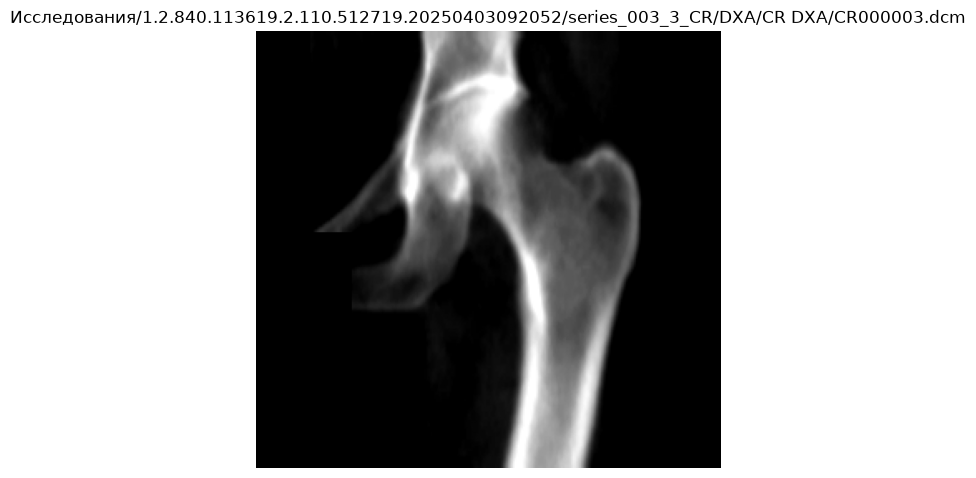

In [ ]:
def show_dicom_array(arr: np.ndarray, title: str = "DICOM", frame_idx: int = 0):
    if arr.ndim == 3:
        image = arr[frame_idx]
        title = f"{title} | frame {frame_idx}/{arr.shape[0] - 1}"
    else:
        image = arr

    plt.figure(figsize=(6, 7))
    plt.imshow(normalize_for_display(image), cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()


show_dicom_array(arr, title=member)


## 7. Просмотр всех frame/slice внутри multi-frame DICOM

В текущих DXA-файлах чаще встречается один кадр на DICOM. Но эта ячейка пригодится, если попадется multi-frame DICOM.


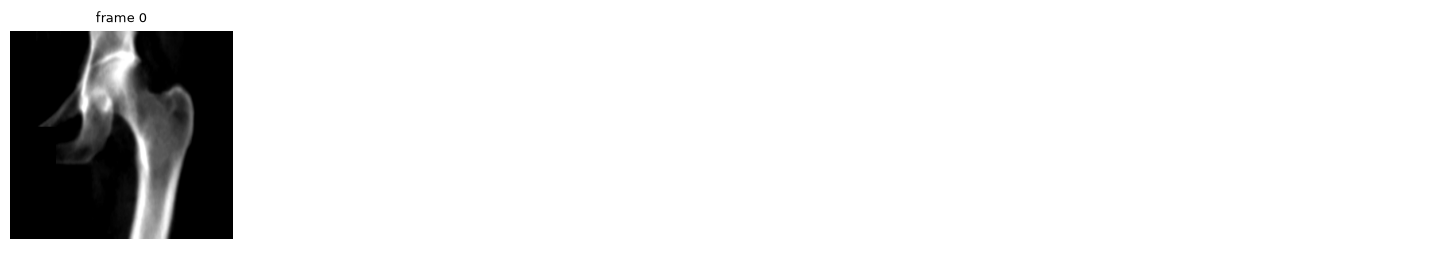

In [ ]:
def show_frames(arr: np.ndarray, max_frames: int = 24, cols: int = 6):
    frames = arr if arr.ndim == 3 else arr[None, ...]
    n = min(len(frames), max_frames)
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.4, rows * 2.8))
    axes = np.array(axes).reshape(-1)

    for i, ax in enumerate(axes):
        ax.axis("off")
        if i >= n:
            continue
        ax.imshow(normalize_for_display(frames[i]), cmap="gray")
        ax.set_title(f"frame {i}", fontsize=9)

    plt.tight_layout()
    plt.show()


show_frames(arr)


## 8. Просмотр всех DICOM внутри одного study

Это ближе к нашей задаче: в `study` лежит несколько DICOM-изображений, среди них могут быть позвоночник, правое бедро, левое бедро и дополнительные/повторные изображения.


Всего study: 100


,study_number,study_folder,n_dicoms,series
0,1,1.2.840.113619.2.110.512719.20250403090444,6,1
1,2,1.2.840.113619.2.110.512719.20250403092052,6,1
2,3,1.2.840.113619.2.110.512719.20250407113211,6,1
3,4,2.25.10245777060263212829333021434108890537,3,1
4,5,2.25.102755089973625799055786462646268820450,6,1
5,6,2.25.102965897799404973225419898683246248872,3,1
6,7,2.25.103868781101960771917584077315578649178,3,1
7,8,2.25.105033841136787477881326326053319223817,6,1
8,9,2.25.108537195937431169718850276671337677972,1,1
9,10,2.25.11175860580562939441493697221497597640,6,1


study_number=28, study_folder=2.25.13325817932854000792938662637654885530, n_dicoms=13, series=1


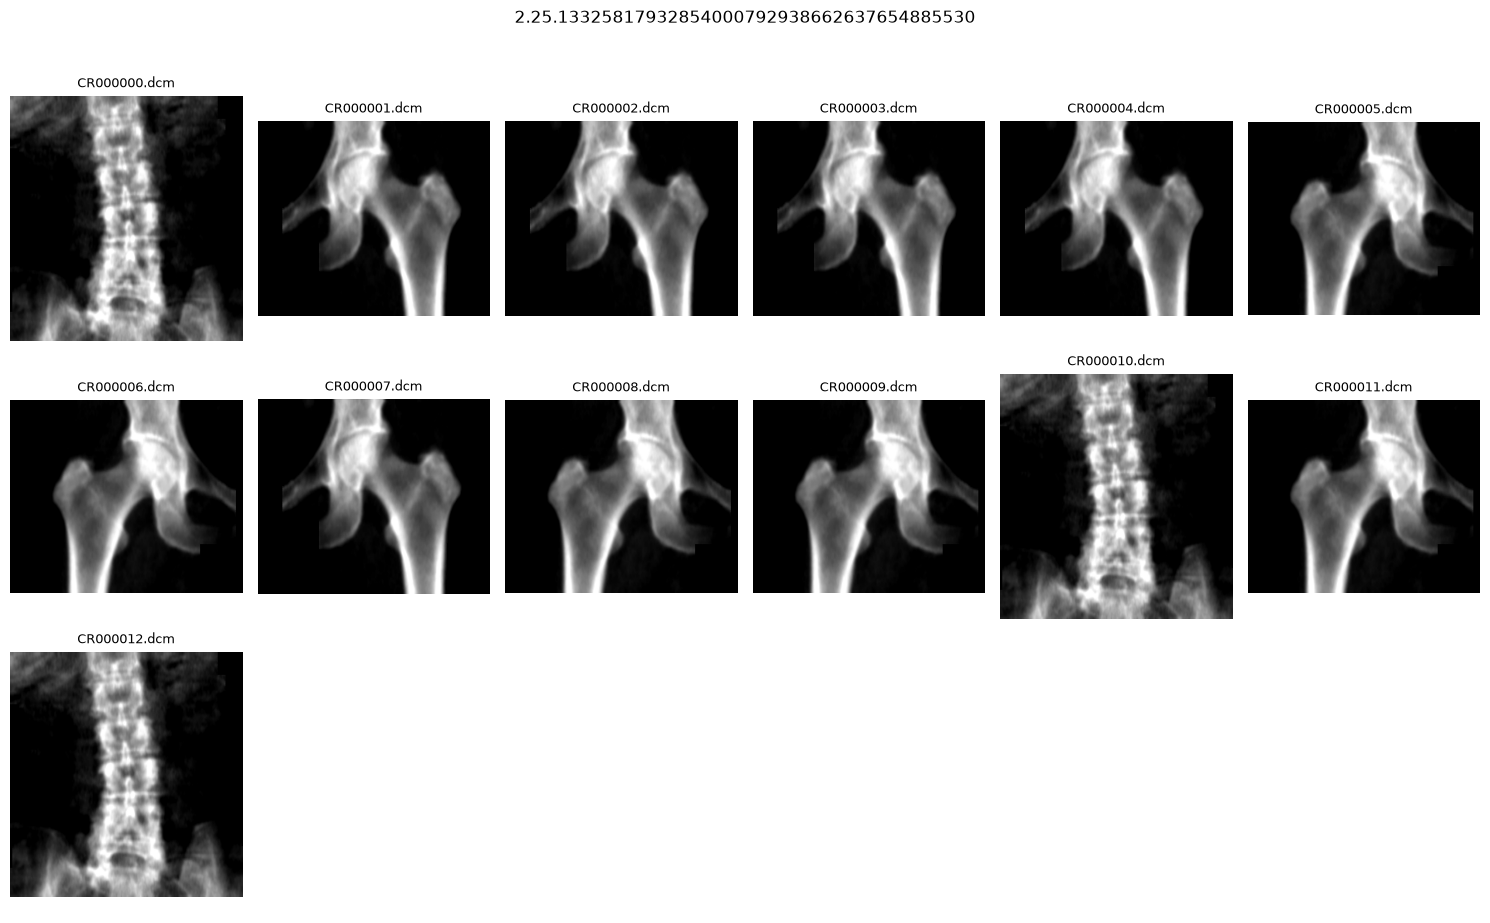

In [11]:
# Эта ячейка теперь сама доопределяет нужные функции, если ты не запускал разделы 2-5.
# Минимально перед ней должен быть запущен первый блок с импортами и путями: ROOT / TRAIN_ZIP / TEST_ZIP.

if "list_dicom_members" not in globals():
    def list_dicom_members(zip_path: Path) -> list[str]:
        with ZipFile(zip_path) as zf:
            return [name for name in zf.namelist() if name.lower().endswith(".dcm")]


if "parse_member_path" not in globals():
    def parse_member_path(member: str) -> dict:
        parts = member.split("/")
        info = {
            "member": member,
            "filename": parts[-1],
            "study_folder": None,
            "series_folder": None,
        }
        if len(parts) >= 3 and parts[0] == "Исследования":
            info["study_folder"] = parts[1]
            info["series_folder"] = parts[2]
        return info


if "read_dicom_from_zip" not in globals():
    def read_dicom_from_zip(zip_path: Path, member: str, stop_before_pixels: bool = False) -> pydicom.Dataset:
        with ZipFile(zip_path) as zf:
            raw = zf.read(member)
        return pydicom.dcmread(BytesIO(raw), stop_before_pixels=stop_before_pixels, force=True)


if "dicom_to_array" not in globals():
    def dicom_to_array(ds: pydicom.Dataset, apply_voi: bool = True) -> np.ndarray:
        arr = ds.pixel_array

        if apply_voi:
            try:
                arr = apply_voi_lut(arr, ds)
            except Exception:
                pass

        arr = arr.astype(np.float32)
        slope = float(getattr(ds, "RescaleSlope", 1.0) or 1.0)
        intercept = float(getattr(ds, "RescaleIntercept", 0.0) or 0.0)
        return arr * slope + intercept


if "normalize_for_display" not in globals():
    def normalize_for_display(arr: np.ndarray, low: float = 1, high: float = 99) -> np.ndarray:
        arr = arr.astype(np.float32)
        lo, hi = np.percentile(arr, [low, high])
        if hi <= lo:
            lo, hi = float(arr.min()), float(arr.max())
        if hi <= lo:
            return np.zeros_like(arr, dtype=np.float32)
        return np.clip((arr - lo) / (hi - lo), 0, 1)


if "train_members" not in globals():
    train_members = list_dicom_members(TRAIN_ZIP)


def members_for_study(members: list[str], study_folder: str) -> list[str]:
    prefix = f"Исследования/{study_folder}/"
    return [m for m in members if m.startswith(prefix)]


def show_study(zip_path: Path, study_folder: str, max_images: int = 18, cols: int = 6):
    members = members_for_study(list_dicom_members(zip_path), study_folder)
    if not members:
        raise ValueError(f"Для study_folder={study_folder!r} не нашел DICOM")

    n = min(len(members), max_images)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 3.0))
    axes = np.array(axes).reshape(-1)

    for i, ax in enumerate(axes):
        ax.axis("off")
        if i >= n:
            continue

        ds_i = read_dicom_from_zip(zip_path, members[i])
        arr_i = dicom_to_array(ds_i)
        image = arr_i[0] if arr_i.ndim == 3 else arr_i

        ax.imshow(normalize_for_display(image), cmap="gray")
        ax.set_title(Path(members[i]).name, fontsize=9)

    plt.suptitle(study_folder, y=1.02, fontsize=12)
    plt.tight_layout()
    plt.show()


study_df = (
    pd.DataFrame([parse_member_path(m) for m in train_members])
    .dropna(subset=["study_folder"])
    .groupby("study_folder", as_index=False)
    .agg(n_dicoms=("member", "count"), series=("series_folder", "nunique"))
    .sort_values("study_folder")
    .reset_index(drop=True)
)
study_df.insert(0, "study_number", np.arange(1, len(study_df) + 1))

print(f"Всего study: {len(study_df)}")
display(study_df.head(20))


def resolve_study_folder(study_selector: int | str) -> str:
    """Принимает либо порядковый номер 1..N, либо строковый UID study_folder."""
    if isinstance(study_selector, str):
        study_selector = study_selector.strip()

        # Если строка содержит только число, считаем ее порядковым номером.
        if study_selector.isdigit():
            study_selector = int(study_selector)
        else:
            matches = study_df.loc[study_df["study_folder"] == study_selector, "study_folder"]
            if matches.empty:
                raise ValueError(
                    f"study_uid={study_selector!r} не найден. "
                    "Проверь, что он есть в колонке study_folder в таблице study_df."
                )
            return matches.iloc[0]

    if isinstance(study_selector, (int, np.integer)):
        if study_selector < 1 or study_selector > len(study_df):
            raise ValueError(f"study_number должен быть от 1 до {len(study_df)}")
        return study_df.loc[study_df["study_number"] == int(study_selector), "study_folder"].iloc[0]

    raise TypeError("study_selector должен быть int номером или str UID исследования")


def show_study_by_selector(study_selector: int | str, max_images: int = 18, cols: int = 6):
    study_folder = resolve_study_folder(study_selector)
    row = study_df.loc[study_df["study_folder"] == study_folder].iloc[0]
    print(
        f"study_number={row['study_number']}, "
        f"study_folder={study_folder}, "
        f"n_dicoms={row['n_dicoms']}, "
        f"series={row['series']}"
    )
    show_study(TRAIN_ZIP, study_folder, max_images=max_images, cols=cols)


# Можно вводить порядковый номер:
# study_selector = 1
# show_study_by_selector(study_selector)

# Или UID исследования из разметки/папки:
study_selector = "2.25.13325817932854000792938662637654885530"
show_study_by_selector(study_selector)


## 9. Быстрый просмотр тестового архива

В тестовом фрагменте файлы лежат без папки `Исследования/...`, поэтому просто покажем все DICOM из архива.


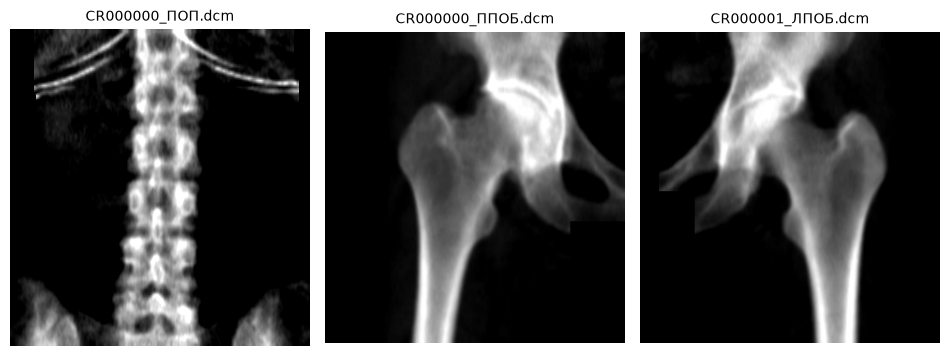

In [36]:
def show_members(zip_path: Path, members: list[str], cols: int = 3):
    n = len(members)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 4.0))
    axes = np.array(axes).reshape(-1)

    for i, ax in enumerate(axes):
        ax.axis("off")
        if i >= n:
            continue
        ds_i = read_dicom_from_zip(zip_path, members[i])
        arr_i = dicom_to_array(ds_i)
        image = arr_i[0] if arr_i.ndim == 3 else arr_i
        ax.imshow(normalize_for_display(image), cmap="gray")
        ax.set_title(Path(members[i]).name, fontsize=10)

    plt.tight_layout()
    plt.show()


show_members(TEST_ZIP, test_members)


## 10. Все теги в виде таблицы

Удобно для первичного EDA: можно искать неожиданные поля, которые пригодятся для группировки или предобработки.


DICOM-тег - это один элемент данных внутри файла. У каждого тега есть:

- `tag`: числовой адрес вида `(gggg,eeee)`, например `(0020,000D)`;
- `keyword`: человекочитаемое имя, например `StudyInstanceUID`;
- `VR`: тип значения, например `UI` для UID, `CS` для code string, `DS` для decimal string;
- `name`: официальное описание;
- `value`: само значение.

Как читать эту таблицу: сначала ищи теги по словам `Study`, `Series`, `SOP`, `Pixel`, `Spacing`, `Body`, `View`, `Laterality`, `Position`. Если `keyword` пустой или тег private, это может быть служебный тег производителя; такие теги стоит смотреть отдельно, но не делать на них ставку без проверки на закрытом тесте.


In [37]:
def dicom_tags_table(ds: pydicom.Dataset, include_private: bool = False) -> pd.DataFrame:
    rows = []
    for elem in ds.iterall():
        if elem.tag.group == 0x7FE0:  # PixelData не выводим в таблицу
            continue
        if elem.tag.is_private and not include_private:
            continue
        value = elem.value
        value_str = str(value)
        if len(value_str) > 160:
            value_str = value_str[:160] + "..."
        rows.append({
            "tag": str(elem.tag),
            "keyword": elem.keyword,
            "VR": elem.VR,
            "name": elem.name,
            "value": value_str,
        })
    return pd.DataFrame(rows)


tags_df = dicom_tags_table(ds)
tags_df.head(50)


,tag,keyword,VR,name,value
0,"(0008,0005)",SpecificCharacterSet,CS,Specific Character Set,ISO_IR 144
1,"(0008,0016)",SOPClassUID,UI,SOP Class UID,1.2.840.10008.5.1.4.1.1.1
2,"(0008,0018)",SOPInstanceUID,UI,SOP Instance UID,1.2.643.5.1.13.13.12.2.77.8252.071203030701061...
3,"(0008,0020)",StudyDate,DA,Study Date,Anonymized
4,"(0008,0022)",AcquisitionDate,DA,Acquisition Date,Anonymized
5,"(0008,0030)",StudyTime,TM,Study Time,Anonymized
6,"(0008,0032)",AcquisitionTime,TM,Acquisition Time,Anonymized
7,"(0008,0050)",AccessionNumber,SH,Accession Number,Anonymized
8,"(0008,0060)",Modality,CS,Modality,CR
9,"(0008,0070)",Manufacturer,LO,Manufacturer,GE Healthcare


In [ ]:
# Быстрые фильтры по интересующим словам.
pattern = "UID|Pixel|Spacing|Body|View|Laterality|Position|Description|Protocol|Rows|Columns"
interesting_tags = tags_df[
    tags_df["keyword"].str.contains(pattern, case=False, na=False)
    | tags_df["name"].str.contains(pattern, case=False, na=False)
]
interesting_tags


In [ ]:
# Private-теги иногда содержат данные производителя. Смотрим их отдельно и осторожно.
private_tags_df = dicom_tags_table(ds, include_private=True)
private_tags_df[private_tags_df["keyword"].eq("")].head(50)
